# 03 · Clustering geográfico e índice de oportunidad comercial

Extiende el análisis de habilitaciones comerciales de la CABA con **ML no
supervisado** y un **índice de oportunidad** por combinación (comuna, rubro).

**Objetivo de negocio**: responder a quien quiere abrir un local comercial
*"¿en qué comuna y en qué rubro conviene abrir?"*.

| Sección | Qué hace |
|---|---|
| 1 | Preparación |
| 2 | Selección de `k` con *silhouette* |
| 3 | Clustering de comunas (KMeans) |
| 4 | Segmentación espacial (DBSCAN) |
| 5 | Tabla (comuna × rubro) |
| 6 | Índice de oportunidad 0-100 |
| 7 | Recomendaciones y visualización |

> **Limitación importante**: el `anio` del padrón refleja el archivo de
> origen, no una serie temporal limpia (faltan 2016-2018 y 2022). El
> crecimiento se calcula sobre la **cuota relativa** del rubro dentro de su
> comuna, no sobre el conteo crudo, para que el efecto "año con más datos"
> no contamine el resultado.


## 1 · Preparación

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.oportunidad import (
    clusterizar_comunas,
    evaluar_k,
    indice_oportunidad,
    preparar_features_comuna_rubro,
    recomendar,
)

plt.rcParams["figure.dpi"] = 110

df = pd.read_csv(
    RAIZ / "data" / "processed" / "habilitaciones_caba_clean.csv",
    encoding="utf-8",
    low_memory=False,
)
print(f"dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas")
df[["comuna", "descripcion_rubro", "anio", "tipo_tramite", "superficie"]].head(3)

dataset: 216,991 filas x 20 columnas


,comuna,descripcion_rubro,anio,tipo_tramite,superficie
0,3.0,OFICINA COMERCIAL,2015,Habilitación,0.0
1,10.0,Acabado de productos textiles,2015,Habilitación,0.0
2,4.0,ACTIVIDADES TIC SEGÚN LEY 2972 - PRODUCCIÓN DE...,2015,Habilitación,300.0


### Año de referencia

Antes de modelar, miramos la **cobertura por año**. El padrón tiene años con
volúmenes muy distintos, y eso condiciona cualquier métrica de crecimiento.

In [2]:
cobertura = df["anio"].value_counts().sort_index()
print("cobertura por año:")
print(cobertura.to_string())
print(f"\n2015 concentra el {100 * cobertura.loc[2015] / len(df):.1f}% del padrón")

cobertura por año:
anio
2015    137463
2019     18861
2020      4585
2021     26117
2023      1616
2024      2746
2025     25601
2026         2

2015 concentra el 63.3% del padrón


## 2 · Selección de `k` con *silhouette*

No elegimos el número de clusters a ojo: evaluamos de 2 a 8 y nos quedamos
con el que maximiza el *silhouette score* (más cercano a 1 = mejor separación).

,k,silhouette,cluster_mas_grande,cluster_mas_chico
0,2,0.3505,12,3
1,3,0.3390,8,3
2,4,0.3366,7,1
3,5,0.3834,7,2
4,6,0.3775,7,1
5,7,0.3412,5,1
6,8,0.2750,4,1


Mejor k = 5


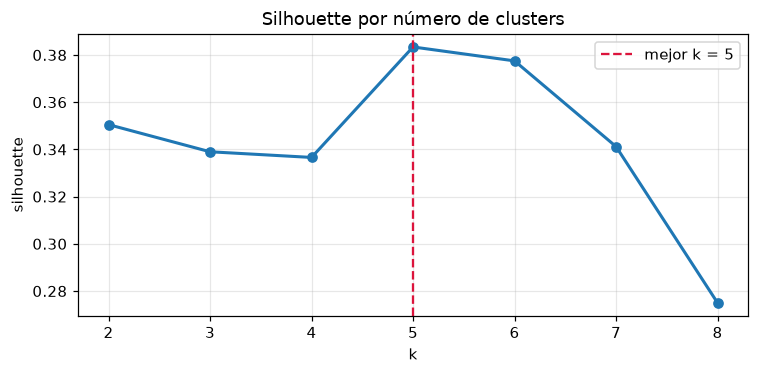

In [3]:
tabla_k = evaluar_k(df, k_min=2, k_max=8)
display(tabla_k)

mejor_k = int(tabla_k.loc[tabla_k["silhouette"].idxmax(), "k"])
print(f"Mejor k = {mejor_k}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(tabla_k["k"], tabla_k["silhouette"], marker="o", lw=2)
ax.axvline(mejor_k, color="crimson", ls="--", label=f"mejor k = {mejor_k}")
ax.set(xlabel="k", ylabel="silhouette", title="Silhouette por número de clusters")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3 · Clustering de comunas (KMeans)

In [4]:
comunas = clusterizar_comunas(df, k=mejor_k, metodo="kmeans")
display(comunas)

print("Tamaño de cada cluster:")
print(comunas["cluster"].value_counts().sort_index().to_string())

,n_licencias,rubros_distintos,superficie_promedio,tasa_nuevas,diversidad_top10,cluster
comuna,,,,,,
1,25864,420,34.804748,0.659063,0.560862,2
2,10796,267,24.039459,0.728881,0.505176,4
3,30401,420,17.354298,0.804316,0.588930,2
4,9063,506,56.796866,0.768399,0.695971,3
5,9119,346,23.023577,0.844720,0.625226,0
6,7607,279,18.823058,0.825950,0.581644,0
7,14612,368,25.347180,0.848207,0.576056,0
8,3735,396,58.314592,0.769210,0.689777,3
9,9941,451,24.442611,0.777890,0.670049,1


Tamaño de cada cluster:
cluster
0    7
1    2
2    2
3    2
4    2


,comunas,licencias_medias,rubros_medios,superficie_media,tasa_nuevas,diversidad
cluster,,,,,,
0,7,11197.57,340.0,24.98,0.82,0.60
1,2,11904.50,502.5,27.77,0.78,0.68
2,2,28132.50,420.0,26.08,0.73,0.57
3,2,6399.00,451.0,57.56,0.77,0.69
4,2,14004.00,291.5,24.29,0.71,0.51


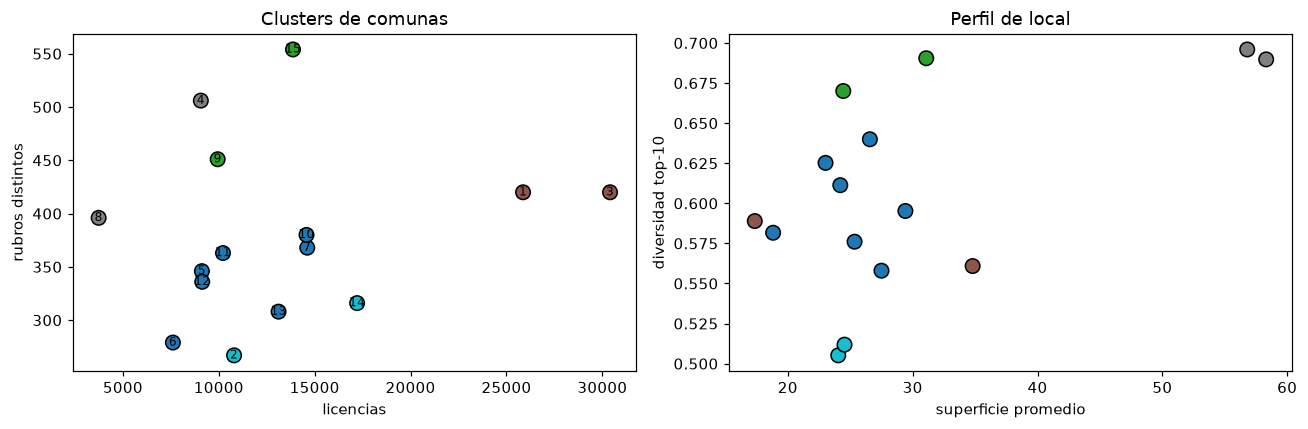

In [5]:
resumen = comunas.groupby("cluster").agg(
    comunas=("n_licencias", "size"),
    licencias_medias=("n_licencias", "mean"),
    rubros_medios=("rubros_distintos", "mean"),
    superficie_media=("superficie_promedio", "mean"),
    tasa_nuevas=("tasa_nuevas", "mean"),
    diversidad=("diversidad_top10", "mean"),
).round(2)
display(resumen)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(comunas["n_licencias"], comunas["rubros_distintos"],
                c=comunas["cluster"], cmap="tab10", s=90, edgecolor="k")
for comuna, fila in comunas.iterrows():
    axes[0].annotate(str(comuna), (fila["n_licencias"], fila["rubros_distintos"]),
                     fontsize=8, ha="center", va="center")
axes[0].set(xlabel="licencias", ylabel="rubros distintos",
            title="Clusters de comunas")
axes[1].scatter(comunas["superficie_promedio"], comunas["diversidad_top10"],
                c=comunas["cluster"], cmap="tab10", s=90, edgecolor="k")
axes[1].set(xlabel="superficie promedio", ylabel="diversidad top-10",
            title="Perfil de local")
plt.tight_layout()
plt.show()

## 4 · Segmentación espacial (DBSCAN)

DBSCAN agrupa por **densidad geográfica**, sin decirle de antemano cuántos
grupos hay. Útil para detectar *clusters* naturales de actividad comercial.

In [6]:
comunas_db = clusterizar_comunas(df, metodo="dbscan", eps=0.8, min_samples=3)
print("DBSCAN -> etiquetas:", sorted(comunas_db["cluster"].unique().tolist()))
display(comunas_db[["n_licencias", "rubros_distintos", "cluster"]])

ruido = int((comunas_db["cluster"] == -1).sum())
print(f"Comunas marcadas como ruido (-1): {ruido} de {len(comunas_db)}")

DBSCAN -> etiquetas: [-1]


,n_licencias,rubros_distintos,cluster
comuna,,,
1,25864,420,-1
2,10796,267,-1
3,30401,420,-1
4,9063,506,-1
5,9119,346,-1
6,7607,279,-1
7,14612,368,-1
8,3735,396,-1
9,9941,451,-1


Comunas marcadas como ruido (-1): 15 de 15


## 5 · Tabla (comuna × rubro)

Agrupamos por combinación y calculamos las métricas que alimentan el índice:
volumen, crecimiento de la cuota, saturación y subrepresentación.

In [7]:
tabla = preparar_features_comuna_rubro(df, top_rubros=80, min_licencias=10)
print(f"combinaciones (comuna, rubro): {len(tabla):,}")
display(tabla.head(10))

combinaciones (comuna, rubro): 1,058


n_licencias  \
comuna rubro                                                             
1      AGENCIA DE LOTERIA NACIONAL, PRODE, etc.,                    86   
       AGENCIAS COMERCIALES DE EMPLEO,TURISMO, INMOBIL...          609   
       Alimentación en general y gastronomía                       104   
       CAFÉ BAR                                                    814   
       CASA DE COMIDAS ROTISERIA                                   448   
       CASA DE LUNCH                                               566   
       COM MIN. DE LIBROS Y REVISTAS                               100   
       COM. MIN. DE REPUESTOS Y ACCESORIOS PARA AUTOMO...           23   
       COM. MIN. VENTA DE ART.P/ ANI MALES DOMESTICOS ...           36   
       COM.MAY. DE ART.DE PERFUMERIA Y TOCADOR (C/DEPO...           13   

                                                           superficie_promedio  \
comuna rubro                                                                     
1      AGENCIA DE LOTERIA NACIONAL, PRODE, etc.,                      1.837209   
       AGENCIAS COMERCIALES DE EMPLEO,TURISMO, INMOBIL...            10.627258   
       Alimentación en general y gastronomía                          9.153846   
       CAFÉ BAR                                                      10.470516   
       CASA DE COMIDAS ROTISERIA                                      9.444196   
       CASA DE LUNCH                                                  9.381625   
       COM MIN. DE LIBROS Y REVISTAS                                 14.520000   
       COM. MIN. DE REPUESTOS Y ACCESORIOS PARA AUTOMO...             7.130435   
       COM. MIN. VENTA DE ART.P/ ANI MALES DOMESTICOS ...             0.000000   
       COM.MAY. DE ART.DE PERFUMERIA Y TOCADOR (C/DEPO...            61.000000   

                                                           crecimiento  \
comuna rubro                                                             
1      AGENCIA DE LOTERIA NACIONAL, PRODE, etc.,             -0.285456   
       AGENCIAS COMERCIALES DE EMPLEO,TURISMO, INMOBIL...    -0.025769   
       Alimentación en general y gastronomía                  0.000000   
       CAFÉ BAR                                              -0.022382   
       CASA DE COMIDAS ROTISERIA                             -0.089836   
       CASA DE LUNCH                                         -0.000106   
       COM MIN. DE LIBROS Y REVISTAS                         -0.071926   
       COM. MIN. DE REPUESTOS Y ACCESORIOS PARA AUTOMO...    -0.024455   
       COM. MIN. VENTA DE ART.P/ ANI MALES DOMESTICOS ...    -0.096460   
       COM.MAY. DE ART.DE PERFUMERIA Y TOCADOR (C/DEPO...     0.057951   

                                                           n_nuevas  \
comuna rubro                                                          
1      AGENCIA DE LOTERIA NACIONAL, PRODE, etc.,               83.0   
       AGENCIAS COMERCIALES DE EMPLEO,TURISMO, INMOBIL...     477.0   
       Alimentación en general y gastronomía                  104.0   
       CAFÉ BAR                                               631.0   
       CASA DE COMIDAS ROTISERIA                              392.0   
       CASA DE LUNCH                                          418.0   
       COM MIN. DE LIBROS Y REVISTAS                           86.0   
       COM. MIN. DE REPUESTOS Y ACCESORIOS PARA AUTOMO...      18.0   
       COM. MIN. VENTA DE ART.P/ ANI MALES DOMESTICOS ...      31.0   
       COM.MAY. DE ART.DE PERFUMERIA Y TOCADOR (C/DEPO...       8.0   

                                                           saturacion  \
comuna rubro                                                            
1      AGENCIA DE LOTERIA NACIONAL, PRODE, etc.,             0.318790   
       AGENCIAS COMERCIALES DE EMPLEO,TURISMO, INMOBIL...    2.257476   
       Alimentación en general y gastronomía                 0.385513   
       CAFÉ BAR                                              3.017382   
     

In [8]:
display(tabla[["n_licencias", "crecimiento", "saturacion", "subrepresentacion"]]
        .describe().round(3))

,n_licencias,crecimiento,saturacion,subrepresentacion
count,1058.000,1058.000,1058.000,1058.000
mean,143.934,-0.016,1.000,-0.154
std,216.391,0.097,1.173,0.789
min,10.000,-0.333,0.036,-5.907
25%,34.000,-0.077,0.278,-0.374
50%,69.000,-0.003,0.563,-0.007
75%,156.750,0.048,1.227,0.268
max,2245.000,0.271,7.997,0.966


## 6 · Índice de oportunidad (0-100)

Fórmula documentada (ver `src/oportunidad.py`):

$$\text{oportunidad} = 100 \times \big( 0{,}40 \cdot \widetilde{crecimiento} + 0{,}40 \cdot (1 - \widetilde{saturacion}) + 0{,}20 \cdot \widetilde{subrepresentacion} \big)$$

donde $\widetilde{x}$ es la normalización min-max a $[0,1]$.

* **crecimiento**: el rubro gana cuota dentro de la comuna.
* **baja saturación**: hay pocas licencias de ese rubro en la comuna.
* **subrepresentación**: el rubro está por debajo de lo esperado en esa comuna.

n_licencias  \
comuna rubro                                                             
1      AGENCIA DE LOTERIA NACIONAL, PRODE, etc.,                    86   
       AGENCIAS COMERCIALES DE EMPLEO,TURISMO, INMOBIL...          609   
       Alimentación en general y gastronomía                       104   
       CAFÉ BAR                                                    814   
       CASA DE COMIDAS ROTISERIA                                   448   
       CASA DE LUNCH                                               566   
       COM MIN. DE LIBROS Y REVISTAS                               100   
       COM. MIN. DE REPUESTOS Y ACCESORIOS PARA AUTOMO...           23   
       COM. MIN. VENTA DE ART.P/ ANI MALES DOMESTICOS ...           36   
       COM.MAY. DE ART.DE PERFUMERIA Y TOCADOR (C/DEPO...           13   

                                                           superficie_promedio  \
comuna rubro                                                                     
1      AGENCIA DE LOTERIA NACIONAL, PRODE, etc.,                      1.837209   
       AGENCIAS COMERCIALES DE EMPLEO,TURISMO, INMOBIL...            10.627258   
       Alimentación en general y gastronomía                          9.153846   
       CAFÉ BAR                                                      10.470516   
       CASA DE COMIDAS ROTISERIA                                      9.444196   
       CASA DE LUNCH                                                  9.381625   
       COM MIN. DE LIBROS Y REVISTAS                                 14.520000   
       COM. MIN. DE REPUESTOS Y ACCESORIOS PARA AUTOMO...             7.130435   
       COM. MIN. VENTA DE ART.P/ ANI MALES DOMESTICOS ...             0.000000   
       COM.MAY. DE ART.DE PERFUMERIA Y TOCADOR (C/DEPO...            61.000000   

                                                           crecimiento  \
comuna rubro                                                             
1      AGENCIA DE LOTERIA NACIONAL, PRODE, etc.,             -0.285456   
       AGENCIAS COMERCIALES DE EMPLEO,TURISMO, INMOBIL...    -0.025769   
       Alimentación en general y gastronomía                  0.000000   
       CAFÉ BAR                                              -0.022382   
       CASA DE COMIDAS ROTISERIA                             -0.089836   
       CASA DE LUNCH                                         -0.000106   
       COM MIN. DE LIBROS Y REVISTAS                         -0.071926   
       COM. MIN. DE REPUESTOS Y ACCESORIOS PARA AUTOMO...    -0.024455   
       COM. MIN. VENTA DE ART.P/ ANI MALES DOMESTICOS ...    -0.096460   
       COM.MAY. DE ART.DE PERFUMERIA Y TOCADOR (C/DEPO...     0.057951   

                                                           n_nuevas  \
comuna rubro                                                          
1      AGENCIA DE LOTERIA NACIONAL, PRODE, etc.,               83.0   
       AGENCIAS COMERCIALES DE EMPLEO,TURISMO, INMOBIL...     477.0   
       Alimentación en general y gastronomía                  104.0   
       CAFÉ BAR                                               631.0   
       CASA DE COMIDAS ROTISERIA                              392.0   
       CASA DE LUNCH                                          418.0   
       COM MIN. DE LIBROS Y REVISTAS                           86.0   
       COM. MIN. DE REPUESTOS Y ACCESORIOS PARA AUTOMO...      18.0   
       COM. MIN. VENTA DE ART.P/ ANI MALES DOMESTICOS ...      31.0   
       COM.MAY. DE ART.DE PERFUMERIA Y TOCADOR (C/DEPO...       8.0   

                                                           saturacion  \
comuna rubro                                                            
1      AGENCIA DE LOTERIA NACIONAL, PRODE, etc.,             0.318790   
       AGENCIAS COMERCIALES DE EMPLEO,TURISMO, INMOBIL...    2.257476   
       Alimentación en general y gastronomía                 0.385513   
       CAFÉ BAR                                              3.017382   
     

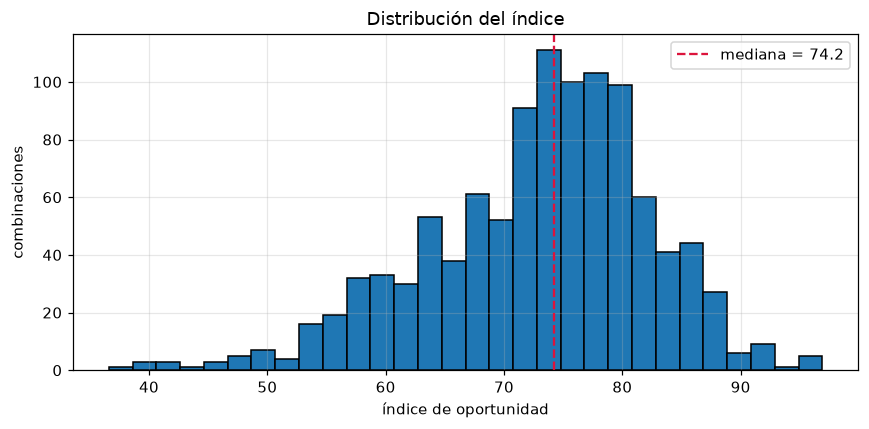

In [9]:
opp = indice_oportunidad(tabla)
display(opp.head(10))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(opp["oportunidad"], bins=30, edgecolor="k")
ax.axvline(opp["oportunidad"].median(), color="crimson", ls="--",
           label=f"mediana = {opp['oportunidad'].median():.1f}")
ax.set(xlabel="índice de oportunidad", ylabel="combinaciones",
       title="Distribución del índice")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7 · Recomendaciones

In [10]:
print("=== TOP 10 oportunidades generales ===")
display(recomendar(opp, top_n=10, min_licencias=20))

=== TOP 10 oportunidades generales ===


n_licencias  \
comuna rubro                                                             
4      COM.MAY.DE ARTIC.PERSONALES Y DE REGALOS(C/DEPO...           30   
10     COM.MIN.DE TEXTILES PARA TAPICERIA                           26   
4      Fabricación de prendas de vestir n.c.p., except...           25   
7      PARRILLA                                                     25   
12     Fabricación de prendas de vestir, excepto prend...           22   
9      COM.MIN. - MAXIQUIOSCO                                       49   
       PARRILLA                                                     47   
10     COM. MIN. DE REPUESTOS Y ACCESORIOS PARA AUTOMO...           56   
       Reparaciones eléctricas, del tablero e instrume...           38   
4      Fabricación de artículos confeccionados de mate...           26   

                                                           crecimiento  \
comuna rubro                                                             
4      COM.MAY.DE ARTIC.PERSONALES Y DE REGALOS(C/DEPO...     0.270825   
10     COM.MIN.DE TEXTILES PARA TAPICERIA                     0.248450   
4      Fabricación de prendas de vestir n.c.p., except...     0.254713   
7      PARRILLA                                               0.180814   
12     Fabricación de prendas de vestir, excepto prend...     0.167408   
9      COM.MIN. - MAXIQUIOSCO                                 0.232319   
       PARRILLA                                               0.232319   
10     COM. MIN. DE REPUESTOS Y ACCESORIOS PARA AUTOMO...     0.191130   
       Reparaciones eléctricas, del tablero e instrume...     0.185333   
4      Fabricación de artículos confeccionados de mate...     0.145951   

                                                           saturacion  \
comuna rubro                                                            
4      COM.MAY.DE ARTIC.PERSONALES Y DE REGALOS(C/DEPO...    0.397005   
10     COM.MIN.DE TEXTILES PARA TAPICERIA                    0.183519   
4      Fabricación de prendas de vestir n.c.p., except...    0.330838   
7      PARRILLA                                              0.170306   
12     Fabricación de prendas de vestir, excepto prend...    0.212606   
9      COM.MIN. - MAXIQUIOSCO                                0.482080   
       PARRILLA                                              0.462403   
10     COM. MIN. DE REPUESTOS Y ACCESORIOS PARA AUTOMO...    0.395271   
       Reparaciones eléctricas, del tablero e instrume...    0.268220   
4      Fabricación de artículos confeccionados de mate...    0.344071   

                                                           subrepresentacion  \
comuna rubro                                                                   
4      COM.MAY.DE ARTIC.PERSONALES Y DE REGALOS(C/DEPO...           0.536432   
10     COM.MIN.DE TEXTILES PARA TAPICERIA                           0.058404   
4      Fabricación de prendas de vestir n.c.p., except...          -0.699750   
7      PARRILLA                                                     0.530376   
12     Fabricación de prendas de vestir, excepto prend...           0.805933   
9      COM.MIN. - MAXIQUIOSCO                                      -0.327525   
       PARRILLA                                                    -0.420817   
10     COM. MIN. DE REPUESTOS Y ACCESORIOS PARA AUTOMO...          -0.249847   
       Reparaciones eléctricas, del tablero e instrume...          -0.418229   
4      Fabricación de artículos confeccionados de mate...           0.527795   

                                                           oportunidad  
comuna rubro                                                            
4      COM.MAY.DE ARTIC.PERSONALES Y DE REGALOS(C/DEPO...         96.9  
10     COM.MIN.DE TEXTILES PARA TAPICERIA                         95.1  
4      Fabricación de prendas de vestir n.c.p., except...         92.6  
7      PARRILLA                                                   92.1  
12   

In [11]:
print("=== ¿Dónde abrir una PARRILLA? ===")
display(recomendar(opp, rubro="PARRILLA", top_n=10, min_licencias=10))

=== ¿Dónde abrir una PARRILLA? ===


,,n_licencias,crecimiento,saturacion,subrepresentacion,oportunidad
comuna,rubro,,,,,
7,PARRILLA,25,0.180814,0.170306,0.530376,92.1
9,PARRILLA,47,0.232319,0.462403,-0.420817,91.3
6,PARRILLA,25,0.091287,0.275138,0.103353,84.4
13,PARRILLA,55,0.089663,0.347695,-0.150537,83.2
10,PARRILLA,29,0.024797,0.204694,0.449661,81.3
5,PARRILLA,45,0.047765,0.452690,-0.411130,79.1
15,PARRILLA,55,0.035343,0.456772,-0.259563,78.7
14,PARRILLA,110,0.043784,0.493555,-0.685039,77.9
4,PARRILLA,39,0.033832,0.516107,-0.460633,77.7


In [12]:
print("=== Gastronomía en la Comuna 1 (Almagro/Boedo) ===")
display(recomendar(opp, comuna=1, rubro="COMIDA", top_n=10, min_licencias=5))

=== Gastronomía en la Comuna 1 (Almagro/Boedo) ===


,,n_licencias,crecimiento,saturacion,subrepresentacion,oportunidad
comuna,rubro,,,,,
1,CASA DE COMIDAS ROTISERIA,448,-0.089836,1.660672,-0.262912,64.4


In [13]:
print("=== ¿Dónde abrir un LOCUTORIO? ===")
display(recomendar(opp, rubro="LOCUTORIO", top_n=10, min_licencias=10))

=== ¿Dónde abrir un LOCUTORIO? ===


,,n_licencias,crecimiento,saturacion,subrepresentacion,oportunidad
comuna,rubro,,,,,
10,LOCUTORIO,15,0.060888,0.105876,0.564713,84.6
12,LOCUTORIO,13,0.000000,0.125631,0.383278,79.9
7,LOCUTORIO,26,0.000000,0.177118,0.253146,79.3
2,LOCUTORIO,24,0.000000,0.168707,0.105026,78.9
6,LOCUTORIO,16,0.000000,0.176088,0.122487,78.9
11,LOCUTORIO,17,-0.017707,0.170310,0.272528,78.2
15,LOCUTORIO,23,-0.044589,0.191014,0.194552,76.1
13,LOCUTORIO,39,-0.082137,0.246547,-0.247540,72.0
1,LOCUTORIO,90,-0.131962,0.333617,-0.482806,67.6


## Conclusiones

1. **El clustering separó las comunas por perfil**, no por tamaño: hay comunas
   grandes pero poco diversas y comunas chicas con mucha variedad de rubros.
2. **El índice prioriza rubros con crecimiento y poca saturación** en comunas
   donde están subrepresentados.
3. **La limitación del `anio`** obligó a medir el crecimiento sobre la cuota
   relativa; esto está documentado en `src/oportunidad.py` para que sea
   auditable.

### Próximos pasos
- Integrar el **Código de Habilitaciones** (PDF) en un RAG para responder
  *requisitos por rubro*.
- Conectar el **SITIO del GCBA** para zonificación / uso de suelo.
- Exponer el índice vía **API (FastAPI)** y **dashboard (Streamlit)**.
